Step 1 — Install and import libraries

In [12]:
!pip -q install gradio

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import gradio as gr

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

from PIL import Image

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Gradio version:", gr.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Gradio version: 6.30.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Step 2 — Load the MNIST dataset

In [14]:
# Load dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

# Normalize pixel values to 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension for CNN
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Processed training shape:", x_train.shape)
print("Processed testing shape:", x_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Processed training shape: (60000, 28, 28, 1)
Processed testing shape: (10000, 28, 28, 1)


Step 3 — Visualize sample handwritten digits

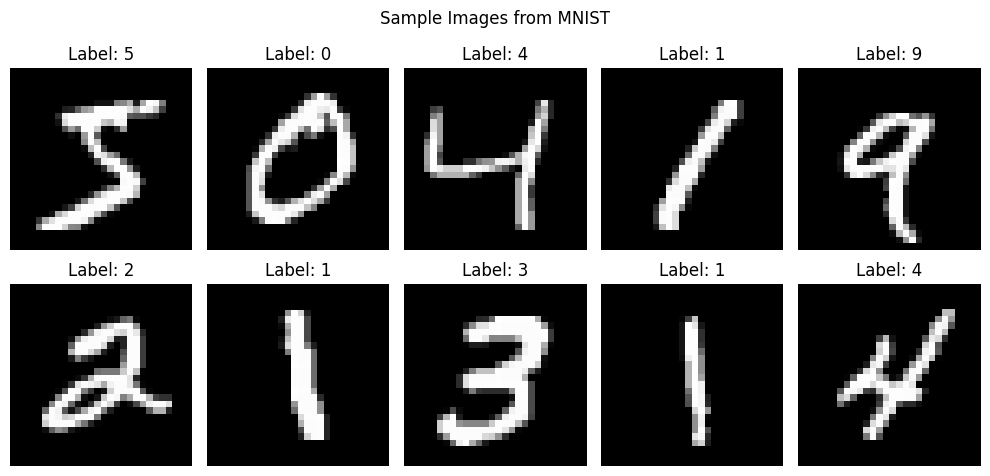

In [15]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Sample Images from MNIST")
plt.tight_layout()
plt.show()

Step 4 — Build the CNN model

In [16]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Step 5 — Train the CNN

In [17]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9188 - loss: 0.2670 - val_accuracy: 0.9827 - val_loss: 0.0580
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9776 - loss: 0.0761 - val_accuracy: 0.9880 - val_loss: 0.0427
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9832 - loss: 0.0547 - val_accuracy: 0.9902 - val_loss: 0.0369
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9864 - loss: 0.0444 - val_accuracy: 0.9900 - val_loss: 0.0333
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9893 - loss: 0.0350 - val_accuracy: 0.9907 - val_loss: 0.0328


Step 6 — Plot training accuracy and loss

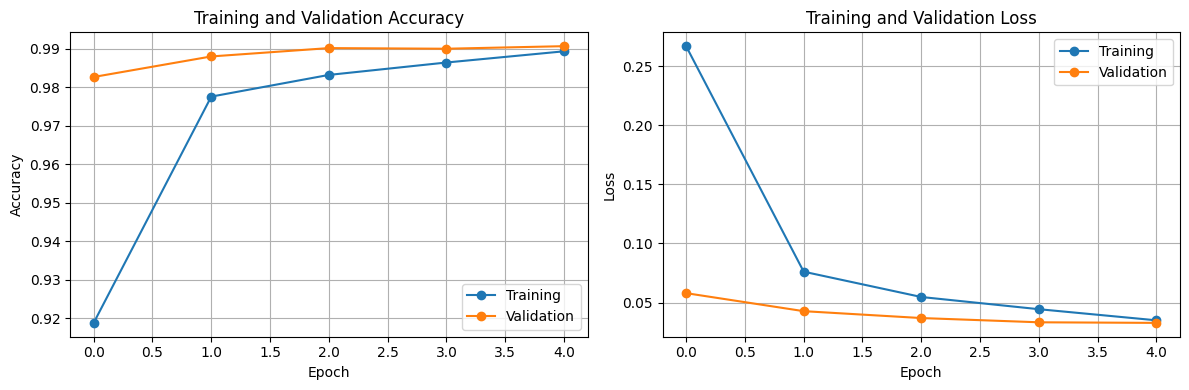

In [18]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Training")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Training")
plt.plot(history.history["val_loss"], marker="o", label="Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Step 7 — Evaluate the model

In [19]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

Test accuracy: 99.04%
Test loss: 0.0277


Step 8 — Generate a confusion matrix

Classification Report:

              precision    recall  f1-score   support

           0     0.9899    0.9969    0.9934       980
           1     0.9938    0.9947    0.9943      1135
           2     0.9884    0.9932    0.9908      1032
           3     0.9930    0.9881    0.9906      1010
           4     0.9909    0.9969    0.9939       982
           5     0.9779    0.9944    0.9861       892
           6     0.9968    0.9791    0.9879       958
           7     0.9951    0.9874    0.9912      1028
           8     0.9808    0.9959    0.9883       974
           9     0.9960    0.9772    0.9865      1009

    accuracy                         0.9904     10000
   macro avg     0.9903    0.9904    0.9903     10000
weighted avg     0.9905    0.9904    0.9904     10000



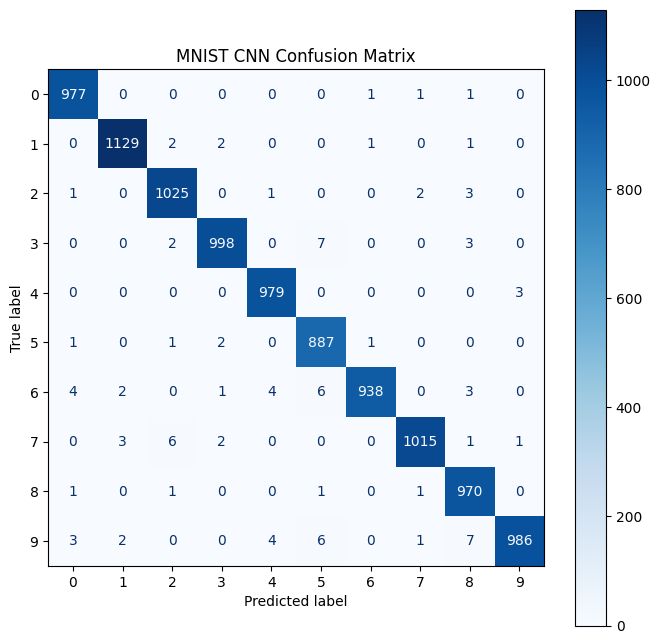

In [20]:
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
).plot(ax=ax, cmap="Blues", values_format="d")

plt.title("MNIST CNN Confusion Matrix")
plt.show()

Step 9 — Save the trained model

In [21]:
model.save("handwritten_digit_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
def recognize_digit(image):
    if image is None:
        return {"Please draw a digit": 1.0}

    # Handle Gradio Sketchpad dictionary output
    if isinstance(image, dict):
        image = image.get("composite")

        if image is None:
            return {"Please draw a digit": 1.0}

    # Convert the drawing into a grayscale image
    if isinstance(image, Image.Image):
        img = image.convert("L")
    else:
        arr = np.asarray(image)

        if arr.ndim == 3 and arr.shape[-1] == 4:
            arr = arr[..., :3]

        if arr.ndim == 3:
            arr = np.mean(arr[..., :3], axis=2)

        img = Image.fromarray(arr.astype(np.uint8)).convert("L")

    arr = np.array(img)

    # Convert white background / black strokes to MNIST style
    if arr.mean() > 127:
        arr = 255 - arr

    arr = np.where(arr > 30, arr, 0).astype(np.uint8)

    # Crop the digit
    ys, xs = np.where(arr > 0)
    if len(xs) == 0:
        return {"Please draw a digit": 1.0}

    digit = Image.fromarray(arr).crop(
        (xs.min(), ys.min(), xs.max() + 1, ys.max() + 1)
    )

    # Resize and center on a 28x28 black canvas
    digit.thumbnail((20, 20))
    canvas = Image.new("L", (28, 28), 0)
    canvas.paste(
        digit,
        ((28 - digit.width) // 2, (28 - digit.height) // 2)
    )

    # Prepare CNN input
    x = np.array(canvas, dtype=np.float32) / 255.0
    x = x.reshape(1, 28, 28, 1)

    # Predict
    probabilities = model.predict(x, verbose=0)[0]

    return {
        str(i): float(probabilities[i])
        for i in range(10)
    }


demo = gr.Interface(
    fn=recognize_digit,
    inputs=gr.Sketchpad(
        type="pil",
        image_mode="L",
        canvas_size=(280, 280),
        label="Draw a digit from 0 to 9"
    ),
    outputs=gr.Label(
        num_top_classes=3,
        label="CNN Prediction"
    ),
    title="Handwritten Digit Recognition Using CNN",
    description="Draw a digit and click Submit to recognize it."
)

demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://2ee5e62f760ad15de4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
